In [30]:
import polars as pl
import folium

In [31]:
#Read df to use
df = pl.read_parquet("../data/output/v2/2.clean_df_v2.parquet")

In [32]:
#-------------------------------
#le nombre total de trajets en 2025 ;
#--------------------------------

print(df.select(pl.count("Total duration (ms)")))

#After cleaning the data, there were 8'762,355 trips made in 2025


shape: (1, 1)
┌─────────────────────┐
│ Total duration (ms) │
│ ---                 │
│ u32                 │
╞═════════════════════╡
│ 8762355             │
└─────────────────────┘


In [33]:
#-------------------------------
# le nombre ou le ratio de stations actives ;
#-------------------------------

#number of active start stations 
print(df.select(pl.col("Start station number").unique_counts()))

#820 start stations where used in 2025

#number of active end stations
print(df.select(pl.col("End station number").unique_counts()))

#822 end stations where used in 2025

#Note, this could change if the 2 stations that only appear in the end station number column are removed in the cleaning step.(station ids 10626 and 22168)




shape: (820, 1)
┌──────────────────────┐
│ Start station number │
│ ---                  │
│ u32                  │
╞══════════════════════╡
│ 15056                │
│ 13531                │
│ 11088                │
│ 13191                │
│ 15764                │
│ …                    │
│ 237                  │
│ 3331                 │
│ 3125                 │
│ 841                  │
│ 37                   │
└──────────────────────┘
shape: (822, 1)
┌────────────────────┐
│ End station number │
│ ---                │
│ u32                │
╞════════════════════╡
│ 10167              │
│ 7337               │
│ 11464              │
│ 22345              │
│ 10075              │
│ …                  │
│ 4396               │
│ 3257               │
│ 3180               │
│ 831                │
│ 27                 │
└────────────────────┘


In [34]:
#Rate of active stations
start_ids = df["Start station number"].unique()
end_ids = df["End station number"].unique()

all_stations = pl.concat([start_ids, end_ids]).unique()

start_rate = start_ids.len() / all_stations.len()
end_rate = end_ids.len() / all_stations.len()

print(f"Start station active rate: {start_rate:.2%}")
print(f"End station active rate:   {end_rate:.2%}")

#almost 100% on both. which is normal actually since the empty stations where already filtered out



Start station active rate: 99.76%
End station active rate:   100.00%


In [35]:
#Most used start and end station
print(df.group_by("Start station number").len().sort("len", descending=True))

print(df.group_by("End station number").len().sort("len", descending=True))


shape: (820, 2)
┌──────────────────────┬───────┐
│ Start station number ┆ len   │
│ ---                  ┆ ---   │
│ i64                  ┆ u32   │
╞══════════════════════╪═══════╡
│ 1072                 ┆ 53880 │
│ 2696                 ┆ 46257 │
│ 1075                 ┆ 42737 │
│ 2587                 ┆ 39851 │
│ 1011                 ┆ 38519 │
│ …                    ┆ …     │
│ 200083444            ┆ 488   │
│ 11274444             ┆ 322   │
│ 1219444              ┆ 250   │
│ 200191444            ┆ 237   │
│ 2635                 ┆ 37    │
└──────────────────────┴───────┘
shape: (822, 2)
┌────────────────────┬───────┐
│ End station number ┆ len   │
│ ---                ┆ ---   │
│ i64                ┆ u32   │
╞════════════════════╪═══════╡
│ 1072               ┆ 50563 │
│ 2696               ┆ 44261 │
│ 960                ┆ 44106 │
│ 1161               ┆ 41383 │
│ 1067               ┆ 40483 │
│ …                  ┆ …     │
│ 11274444           ┆ 274   │
│ 1219444            ┆ 242   │
│ 20

In [36]:
# -------------------------------
# le nombre ou le ratio de stations utilisées comme stations de départ ;
#-------------------------------

#check previous point


#-------------------------------
# le nombre ou le ratio de stations utilisées comme stations d'arrivée ;
#-------------------------------

#check previous point




In [37]:
#-------------------------------
# la distribution du nombre de trajets par jour ;
#-------------------------------

#Change date format to date time
#df = df.with_columns(
#    pl.col("Start date").str.to_datetime("%Y-%m-%d %H:%M"),
#    pl.col("End date").str.to_datetime("%Y-%m-%d %H:%M")
#)
#print(df)


print(df.group_by("Operating date").len().sort("len", descending=True))

#there is a huge gap between the 2 lowest dates: 2025-08-05 with 171 trajets and 2025-01-01 with 5077 trajets (could it be that the missing values removed in the cleaning belonged mostly to 2025-08-05 ?)


shape: (365, 2)
┌────────────────┬───────┐
│ Operating date ┆ len   │
│ ---            ┆ ---   │
│ date           ┆ u32   │
╞════════════════╪═══════╡
│ 2025-09-09     ┆ 44732 │
│ 2025-09-11     ┆ 41080 │
│ 2025-09-08     ┆ 40110 │
│ 2025-09-10     ┆ 36695 │
│ 2025-07-10     ┆ 34028 │
│ …              ┆ …     │
│ 2025-12-24     ┆ 8216  │
│ 2025-12-26     ┆ 6171  │
│ 2025-01-05     ┆ 5739  │
│ 2025-01-01     ┆ 5077  │
│ 2025-08-05     ┆ 171   │
└────────────────┴───────┘


In [38]:
#-------------------------------
# la distribution du nombre de trajets par station ;
#-------------------------------

#Most used start and end station
print(df.group_by("Start station number").len().sort("len", descending=True))

print(df.group_by("End station number").len().sort("len", descending=True))


shape: (820, 2)
┌──────────────────────┬───────┐
│ Start station number ┆ len   │
│ ---                  ┆ ---   │
│ i64                  ┆ u32   │
╞══════════════════════╪═══════╡
│ 1072                 ┆ 53880 │
│ 2696                 ┆ 46257 │
│ 1075                 ┆ 42737 │
│ 2587                 ┆ 39851 │
│ 1011                 ┆ 38519 │
│ …                    ┆ …     │
│ 200083444            ┆ 488   │
│ 11274444             ┆ 322   │
│ 1219444              ┆ 250   │
│ 200191444            ┆ 237   │
│ 2635                 ┆ 37    │
└──────────────────────┴───────┘
shape: (822, 2)
┌────────────────────┬───────┐
│ End station number ┆ len   │
│ ---                ┆ ---   │
│ i64                ┆ u32   │
╞════════════════════╪═══════╡
│ 1072               ┆ 50563 │
│ 2696               ┆ 44261 │
│ 960                ┆ 44106 │
│ 1161               ┆ 41383 │
│ 1067               ┆ 40483 │
│ …                  ┆ …     │
│ 11274444           ┆ 274   │
│ 1219444            ┆ 242   │
│ 20

In [39]:
 
# -------------------------------
# la distribution des durées de trajets ;
#-------------------------------

print(df.group_by("Total duration (ms)").len().sort("len", descending=True))


shape: (2_418_292, 2)
┌─────────────────────┬─────┐
│ Total duration (ms) ┆ len │
│ ---                 ┆ --- │
│ i64                 ┆ u32 │
╞═════════════════════╪═════╡
│ 360953              ┆ 24  │
│ 340310              ┆ 23  │
│ 446246              ┆ 22  │
│ 471958              ┆ 22  │
│ 415027              ┆ 22  │
│ …                   ┆ …   │
│ 1931958             ┆ 1   │
│ 1832493             ┆ 1   │
│ 147417              ┆ 1   │
│ 7211738             ┆ 1   │
│ 3944017             ┆ 1   │
└─────────────────────┴─────┘


In [40]:
#-------------------------------
# la répartition des trajets selon le jour de la semaine ;
#-------------------------------

#Day of week being 1=monday and 7=sunday
print(df.group_by("Day of week").len().sort("len", descending=True))

#lower use of the bicycles is seen on the weekend (6=saturday and 7=sunday)


shape: (7, 2)
┌─────────────┬─────────┐
│ Day of week ┆ len     │
│ ---         ┆ ---     │
│ i8          ┆ u32     │
╞═════════════╪═════════╡
│ 3           ┆ 1417276 │
│ 4           ┆ 1411953 │
│ 2           ┆ 1407982 │
│ 1           ┆ 1257439 │
│ 5           ┆ 1242804 │
│ 6           ┆ 1073299 │
│ 7           ┆ 951602  │
└─────────────┴─────────┘


In [41]:
#-------------------------------
# la répartition des trajets selon l'heure de la journée.
#-------------------------------

print(df.group_by("Hour of day").len().sort("len", descending=True))

#Most used hours are before work and after work. Least used are the night/morning hours (horas de madrugada - heures de nuit)



shape: (24, 2)
┌─────────────┬────────┐
│ Hour of day ┆ len    │
│ ---         ┆ ---    │
│ i8          ┆ u32    │
╞═════════════╪════════╡
│ 17          ┆ 889343 │
│ 8           ┆ 865645 │
│ 18          ┆ 830044 │
│ 16          ┆ 593510 │
│ 9           ┆ 548452 │
│ …           ┆ …      │
│ 5           ┆ 45129  │
│ 1           ┆ 42485  │
│ 2           ┆ 25670  │
│ 4           ┆ 19820  │
│ 3           ┆ 18380  │
└─────────────┴────────┘


In [27]:
#######################
#bike map
#######################

# Chargement des stations
GPS_Point = pl.read_csv("../data/tfl_bike_stations.csv")

GPS_Point = GPS_Point[[
    "station_number",
    "station_name",
    "latitude",
    "longitude"
]]

# Centre approximatif de Londres
london_map = folium.Map(
    location=[51.5074, -0.1278],
    zoom_start=12
)

# Ajout des stations
for row in GPS_Point.drop_nulls(["latitude", "longitude"]).iter_rows(named=True):
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=3,
        popup=f'{row["station_name"]} - {row["station_number"]}',
        fill=True,
        fill_opacity=0.7
    ).add_to(london_map)



# Sauvegarde
london_map.save("stations_londres.html")

london_map

PROFILE STATION ANALYSIS


In [42]:
df

Start date,Start station number,End date,End station number,Total duration (ms),Operating date,Day of week,Hour of day,start_station_latitude,start_station_longitude,start_station_name,end_station_latitude,end_station_longitude,end_station_name
datetime[μs],i64,datetime[μs],i64,i64,date,i8,i8,f64,f64,str,f64,f64,str
2025-01-14 23:59:00,1043,2025-01-15 00:13:00,200149,870468,2025-01-14,2,23,51.517821,-0.096496,"""Museum of London, Barbican""",51.511542,-0.056667,"""Watney Street, Shadwell"""
2025-01-14 23:59:00,300015,2025-01-15 00:04:00,300229,307181,2025-01-14,2,23,51.472509,-0.122831,"""Binfield Road, Stockwell""",51.469202,-0.119022,"""Sidney Road, Stockwell"""
2025-01-14 23:59:00,1068,2025-01-15 00:10:00,1051,640755,2025-01-14,2,23,51.521113,-0.078869,"""Norton Folgate, Liverpool Stre…",51.534042,-0.086379,"""Shoreditch Park, Hoxton"""
2025-01-14 23:59:00,1159,2025-01-15 00:10:00,1007,642548,2025-01-14,2,23,51.522853,-0.099994,"""Berry Street, Clerkenwell""",51.51477,-0.122219,"""Drury Lane, Covent Garden"""
2025-01-14 23:58:00,200048,2025-01-15 00:14:00,1058,944185,2025-01-14,2,23,51.493978,-0.127554,"""Page Street, Westminster""",51.510212,0.004979,"""Orchard Place, Blackwall Tunne…"
…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-16 00:02:00,200141,2025-12-16 00:16:00,200237,837578,2025-12-16,2,0,51.509158,-0.224103,"""Westfield Ariel Way, White Cit…",51.472817,-0.199783,"""Parson's Green , Parson's Gree…"
2025-12-16 00:01:00,200011,2025-12-16 00:16:00,200250,908383,2025-12-16,2,0,51.519265,-0.021345,"""Furze Green, Bow""",51.520893,-0.051394,"""Cleveland Way, Stepney"""
2025-12-16 00:00:00,300096,2025-12-16 00:07:00,962,432164,2025-12-16,2,0,51.511891,-0.107349,"""Tallis Street, Temple""",51.505569,-0.111606,"""Stamford Street, South Bank"""


In [ ]:
df = df.rename({
    "Start date": "start_date",
    "Start station number": "start_station",
    "End date": "end_date",
    "End station number": "end_station",
    "Total duration (ms)": "duration_ms",
    "Operating date": "operating_date",
    "Day of week": "day_of_week",
    "Hour of day": "hour"
})



In [44]:
df

start_date,start_station,end_date,end_station,duration_ms,operating_date,day_of_week,hour,start_station_latitude,start_station_longitude,start_station_name,end_station_latitude,end_station_longitude,end_station_name
datetime[μs],i64,datetime[μs],i64,i64,date,i8,i8,f64,f64,str,f64,f64,str
2025-01-14 23:59:00,1043,2025-01-15 00:13:00,200149,870468,2025-01-14,2,23,51.517821,-0.096496,"""Museum of London, Barbican""",51.511542,-0.056667,"""Watney Street, Shadwell"""
2025-01-14 23:59:00,300015,2025-01-15 00:04:00,300229,307181,2025-01-14,2,23,51.472509,-0.122831,"""Binfield Road, Stockwell""",51.469202,-0.119022,"""Sidney Road, Stockwell"""
2025-01-14 23:59:00,1068,2025-01-15 00:10:00,1051,640755,2025-01-14,2,23,51.521113,-0.078869,"""Norton Folgate, Liverpool Stre…",51.534042,-0.086379,"""Shoreditch Park, Hoxton"""
2025-01-14 23:59:00,1159,2025-01-15 00:10:00,1007,642548,2025-01-14,2,23,51.522853,-0.099994,"""Berry Street, Clerkenwell""",51.51477,-0.122219,"""Drury Lane, Covent Garden"""
2025-01-14 23:58:00,200048,2025-01-15 00:14:00,1058,944185,2025-01-14,2,23,51.493978,-0.127554,"""Page Street, Westminster""",51.510212,0.004979,"""Orchard Place, Blackwall Tunne…"
…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-12-16 00:02:00,200141,2025-12-16 00:16:00,200237,837578,2025-12-16,2,0,51.509158,-0.224103,"""Westfield Ariel Way, White Cit…",51.472817,-0.199783,"""Parson's Green , Parson's Gree…"
2025-12-16 00:01:00,200011,2025-12-16 00:16:00,200250,908383,2025-12-16,2,0,51.519265,-0.021345,"""Furze Green, Bow""",51.520893,-0.051394,"""Cleveland Way, Stepney"""
2025-12-16 00:00:00,300096,2025-12-16 00:07:00,962,432164,2025-12-16,2,0,51.511891,-0.107349,"""Tallis Street, Temple""",51.505569,-0.111606,"""Stamford Street, South Bank"""


In [45]:
'''
#Load df
#df = pl.read_csv("../data/output/v2/2.clean_df_v2.csv")


df = df.with_columns([
    pl.col("start_date").str.to_datetime(strict=False),
    pl.col("end_date").str.to_datetime(strict=False),
    pl.col("operating_date").str.to_date(strict=False),
])
df
'''

'\n#Load df\n#df = pl.read_csv("../data/output/v2/2.clean_df_v2.csv")\n\n\ndf = df.with_columns([\n    pl.col("start_date").str.to_datetime(strict=False),\n    pl.col("end_date").str.to_datetime(strict=False),\n    pl.col("operating_date").str.to_date(strict=False),\n])\ndf\n'

In [46]:
#########################
#Create station profiles
#########################

#-------------------
#departure features
#-------------------
departures = (
    df
    .group_by("start_station")
    .agg([
        pl.len().alias("n_departures"), #number of trips starting at this station

        pl.col("duration_ms").mean().alias("mean_duration"), #average trip duration for trips departing from that station.
        pl.col("duration_ms").median().alias("median_duration"), #median trip duration departing from that station.
        pl.col("duration_ms").std().alias("std_duration"), #standard deviation trip duration departing from that station.

        pl.col("end_station").n_unique().alias("n_destinations"), #Counts the number of different destination stations reached from each starting station.
    ])
    .rename({"start_station": "station"})
)


#--------------------
#arrival features
#--------------------
arrivals = (
    df
    .group_by("end_station")
    .agg([
        pl.len().alias("n_arrivals"), #number of trips arriving at this station

        pl.col("start_station").n_unique().alias("n_origins"), #Counts the number of different destination stations that end in each end station.
    ])
    .rename({"end_station": "station"})
)


#Join them
stations = departures.join(
    arrivals,
    on="station",
    how="full"
).fill_null(0)

stations

station,n_departures,mean_duration,median_duration,std_duration,n_destinations,station_right,n_arrivals,n_origins
i64,u32,f64,f64,f64,u32,i64,u32,u32
300087,7100,3.7196e6,634420.5,1.5408e8,422,300087,6716,433
1087,11477,1.2755e6,836608.0,1.0489e7,664,1087,11954,664
200053,3280,2.1102e6,925209.5,4.0010e7,466,200053,3097,426
300051,10405,1.3385e6,876639.0,1.2515e7,515,300051,10345,543
300069,11232,1.8484e6,705764.5,8.2752e7,569,300069,10123,537
…,…,…,…,…,…,…,…,…
200249,14178,1.4207e6,663074.0,3.0066e7,535,200249,13595,462
200148,14070,1.3533e6,609900.5,2.3829e7,537,200148,13094,509
200127,4970,1.8336e6,965054.5,9.4181e6,379,200127,5497,420


In [47]:
#-------------------
#departure/arrival ratio
#-------------------

stations = stations.with_columns(
    (pl.col('n_departures')/pl.col('n_arrivals')).alias('departure_arrival_ratio')
)

stations

station,n_departures,mean_duration,median_duration,std_duration,n_destinations,station_right,n_arrivals,n_origins,departure_arrival_ratio
i64,u32,f64,f64,f64,u32,i64,u32,u32,f64
300087,7100,3.7196e6,634420.5,1.5408e8,422,300087,6716,433,1.057177
1087,11477,1.2755e6,836608.0,1.0489e7,664,1087,11954,664,0.960097
200053,3280,2.1102e6,925209.5,4.0010e7,466,200053,3097,426,1.059089
300051,10405,1.3385e6,876639.0,1.2515e7,515,300051,10345,543,1.0058
300069,11232,1.8484e6,705764.5,8.2752e7,569,300069,10123,537,1.109553
…,…,…,…,…,…,…,…,…,…
200249,14178,1.4207e6,663074.0,3.0066e7,535,200249,13595,462,1.042883
200148,14070,1.3533e6,609900.5,2.3829e7,537,200148,13094,509,1.074538
200127,4970,1.8336e6,965054.5,9.4181e6,379,200127,5497,420,0.90413


In [48]:
#-------------------
#Avg departures and arrivals per day
#-------------------
daily_departures = (
    df
    .group_by(["operating_date", "start_station"])
    .agg(
        pl.len().alias("departures")
    )
)

daily_arrivals = (
    df
    .group_by(["operating_date", "end_station"])
    .agg(
        pl.len().alias("arrivals")
    )
)

avg_departures = (
    daily_departures
    .group_by("start_station")
    .agg(
        pl.col("departures").mean().alias("avg_daily_departures")
    )
    .rename({"start_station": "station"})
)

avg_arrivals = (
    daily_arrivals
    .group_by("end_station")
    .agg(
        pl.col("arrivals").mean().alias("avg_daily_arrivals")
    )
    .rename({"end_station": "station"})
)

station_daily_avg = (
    avg_departures
    .join(avg_arrivals, on="station", how="left")
    .sort("station")
)

station_daily_avg

station,avg_daily_departures,avg_daily_arrivals
i64,f64,f64
959,25.78022,26.406593
960,100.381868,121.17033
961,28.717033,28.89011
962,30.870523,32.909091
963,33.346154,38.635616
…,…,…
200191444,9.115385,9.192308
200230444,58.301075,56.308511
300032444,26.478261,25.73913


In [49]:
#-----------------------
#Weekend and weekday behavior
#-----------------------
print(
    df
    .select("day_of_week")
    .unique()
    .sort("day_of_week")
)

df = df.with_columns(
    (pl.col("day_of_week") >= 6).alias("is_weekend")
)

print(df)

weekend_profile = (
    df
    .group_by("start_station")
    .agg([
        pl.col("is_weekend").mean().alias("weekend_ratio")
    ])
    .rename({"start_station": "station"})
)

weekend_profile

shape: (7, 1)
┌─────────────┐
│ day_of_week │
│ ---         │
│ i8          │
╞═════════════╡
│ 1           │
│ 2           │
│ 3           │
│ 4           │
│ 5           │
│ 6           │
│ 7           │
└─────────────┘
shape: (8_762_355, 15)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ start_dat ┆ start_sta ┆ end_date  ┆ end_stati ┆ … ┆ end_stati ┆ end_stati ┆ end_stati ┆ is_weeke │
│ e         ┆ tion      ┆ ---       ┆ on        ┆   ┆ on_latitu ┆ on_longit ┆ on_name   ┆ nd       │
│ ---       ┆ ---       ┆ datetime[ ┆ ---       ┆   ┆ de        ┆ ude       ┆ ---       ┆ ---      │
│ datetime[ ┆ i64       ┆ μs]       ┆ i64       ┆   ┆ ---       ┆ ---       ┆ str       ┆ bool     │
│ μs]       ┆           ┆           ┆           ┆   ┆ f64       ┆ f64       ┆           ┆          │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ 2025-01-1 ┆ 1043      ┆ 2025-01-1 ┆ 200149    

station,weekend_ratio
i64,f64
3451,0.246941
200202,0.274472
2635,0.189189
22175,0.281195
1227,0.278899
…,…
2587,0.122858
300036,0.238714
300039,0.305184


In [50]:
#--------------------
#Rush hour features
#--------------------

df = df.with_columns([
    (
        (pl.col("hour") >= 7) &
        (pl.col("hour") <= 9)
    ).alias("morning_rush"),

    (
        (pl.col("hour") >= 17) &
        (pl.col("hour") <= 19)
    ).alias("evening_rush"),

    (
        (pl.col("hour") >= 0) &
        (pl.col("hour") <= 5)
    ).alias("night")
])

rush_profile = (
    df
    .group_by("start_station")
    .agg([
        pl.col("morning_rush").mean().alias("morning_rush_ratio"),
        pl.col("evening_rush").mean().alias("evening_rush_ratio"),
        pl.col("night").mean().alias("night_ratio"),
    ])
    .rename({"start_station": "station"})
)

rush_profile

station,morning_rush_ratio,evening_rush_ratio,night_ratio
i64,f64,f64,f64
1182,0.162008,0.216904,0.037155
200065,0.310618,0.153724,0.012678
200062,0.258586,0.168042,0.031891
1054,0.295089,0.213613,0.044119
3436,0.113115,0.289939,0.016673
…,…,…,…
1152,0.076098,0.390544,0.017561
1000,0.242276,0.233979,0.040656
1167,0.319267,0.274001,0.007213


In [51]:
#-------------------
#Final df -> stations
#-------------------

stations = (
    stations
    #.join(hour_profile, on="station", how="left")
    .join(station_daily_avg, on="station", how="left")
    .join(weekend_profile, on="station", how="left")
    .join(rush_profile, on="station", how="left")
    .fill_null(0)
)

print(stations.shape)

(822, 16)


In [52]:
stations = stations.select(['station','n_departures','avg_daily_departures','n_arrivals','avg_daily_arrivals','departure_arrival_ratio','n_destinations','n_origins','mean_duration','median_duration','std_duration','weekend_ratio','morning_rush_ratio','evening_rush_ratio','night_ratio'])

stations

station,n_departures,avg_daily_departures,n_arrivals,avg_daily_arrivals,departure_arrival_ratio,n_destinations,n_origins,mean_duration,median_duration,std_duration,weekend_ratio,morning_rush_ratio,evening_rush_ratio,night_ratio
i64,u32,f64,u32,f64,f64,u32,u32,f64,f64,f64,f64,f64,f64,f64
300087,7100,19.505495,6716,18.450549,1.057177,422,433,3.7196e6,634420.5,1.5408e8,0.241268,0.296056,0.162113,0.044648
1087,11477,31.53022,11954,32.840659,0.960097,664,664,1.2755e6,836608.0,1.0489e7,0.170428,0.255642,0.272197,0.015684
200053,3280,9.111111,3097,8.53168,1.059089,466,426,2.1102e6,925209.5,4.0010e7,0.21372,0.217378,0.283841,0.031707
300051,10405,28.585165,10345,28.42033,1.0058,515,543,1.3385e6,876639.0,1.2515e7,0.241711,0.35925,0.171552,0.017107
300069,11232,30.857143,10123,27.81044,1.109553,569,537,1.8484e6,705764.5,8.2752e7,0.263088,0.319177,0.17557,0.029113
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
200249,14178,38.950549,13595,37.348901,1.042883,535,462,1.4207e6,663074.0,3.0066e7,0.185922,0.114403,0.247143,0.032092
200148,14070,38.653846,13094,35.972527,1.074538,537,509,1.3533e6,609900.5,2.3829e7,0.267448,0.208458,0.201137,0.027079
200127,4970,13.653846,5497,15.101648,0.90413,379,420,1.8336e6,965054.5,9.4181e6,0.364789,0.214085,0.180885,0.030181


In [53]:
#######################
#export df
#######################

stations.write_csv("../data/output/v2/4.stations_df.csv")


*CLUSTERING*

In [ ]:
#Chose variables to use
feature_columns = ['station','n_departures','avg_daily_departures','n_arrivals','avg_daily_arrivals','departure_arrival_ratio','n_destinations','n_origins','mean_duration','median_duration','std_duration','weekend_ratio','morning_rush_ratio','evening_rush_ratio','night_ratio']


#X = stations.select(feature_columns).to_numpy()

X = stations.to_numpy()


#standarize
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ==========================================================================
# CLAUDE'S FIX -- bug: 'station' is a numeric ID, not a real feature
# ==========================================================================
# Both `X = stations.to_numpy()` above AND the commented-out
# `stations.select(feature_columns)` line include the 'station' column.
# It looks numeric so nothing crashes, but it's just an arbitrary station
# identifier, e.g.:
#   stations['station'].describe() -> min=0, 25%=1170, 50%=22176,
#   75%=200212, max=2,001,454,444
# TfL mixes several id schemes (docking stations vs e-bikes etc.), so this
# "feature" is wildly skewed with one station near 2 billion. Once
# standardized, that single station becomes a huge outlier on this bogus
# dimension and ends up alone in its own K-means cluster later -- this is
# exactly the "cluster completely dedicated to 1 single station" you
# flagged further down. It also slightly distorts every PCA / silhouette /
# inertia number computed in this notebook.
#
# Fix: drop 'station' from the numeric matrix and keep it only as a label.

feature_columns = [c for c in feature_columns if c != 'station']

X = stations.select(feature_columns).to_numpy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:
###################
#PCA
##################

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

#Explained variance
explained_variance = pca.explained_variance_ratio_

for i, variance in enumerate(explained_variance[:10], start=1):
    print(f"PC{i}: {variance:.2%}")

#plot cumulative explained variance

plt.figure(figsize=(8, 5))

plt.plot(
    np.cumsum(explained_variance),
    marker="o"
)

plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA – cumulative explained variance")
plt.grid(alpha=0.3)

plt.show()

#A principal component (PCA) is not one of your original variables. It is a weighted combination of your 37 variables.
#PC1 explains 37.15%
#That means the direction in your 37-dimensional feature space with the largest amount of variation between stations accounts for about 37% of the total variance.

#That's quite substantial.

#PC2 captures another 14.94%, and PC3 another 13.66%.

#Together:

#37.15% + 14.94% + 13.66% = 65.75%
#So three dimensions capture about 65.75% of the variation in your original 37-dimensional dataset.

#-----------
#Graph
#-----------

#It shows How much of the original variation is retained if I keep the first N principal components?

#The first few PCs are doing a lot of work.

#The later PCs each contribute relatively little.

#THE ELBOW IS AROUND 3 OR 4 

#The first few PCs are doing a lot of work.

#The later PCs each contribute relatively little.


# --------------------------------------------------------------------
# CLAUDE'S NOTE -- numbers above were computed with the 'station' ID bug
# --------------------------------------------------------------------
# After the fix in the previous cell, the real explained variance is:
#   PC1: 39.77%   PC2: 16.00%   PC3: 14.62%   (cumulative PC1-3: 70.40%)
# So the story doesn't change much (3 PCs still capture the bulk of the
# variance, elbow still around 3-4), but the exact percentages you quoted
# above (37.15% / 14.94% / 13.66% / 65.75%) belong to the buggy run and
# should be updated to the values above.

In [ ]:
#Visualize stations in PCA space
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.7,
    s=30
)

plt.xlabel(f"PC1 ({explained_variance[0]:.1%})")
plt.ylabel(f"PC2 ({explained_variance[1]:.1%})")
plt.title("Station profiles – PCA")
plt.grid(alpha=0.2)

plt.show()

In [ ]:
####################33
#To interpret pca components
####################3

#Get loadings
loadings = pl.DataFrame({
    "feature": feature_columns,
    "PC1": pca.components_[0].tolist(),
    "PC2": pca.components_[1].tolist(),
    "PC3": pca.components_[2].tolist(),
})

#sort PC1
print(
    loadings
    .sort("PC1", descending=True)
)

#And separately look at the largest absolute contributions:
pc1 = (
    loadings
    .with_columns(
        pl.col("PC1").abs().alias("abs_PC1")
    )
    .sort("abs_PC1", descending=True)
)

print(pc1)

#and pc2
pc2 = (
    loadings
    .with_columns(
        pl.col("PC2").abs().alias("abs_PC2")
    )
    .sort("abs_PC2", descending=True)
)

print(pc2)

#and pc3
pc3 = (
    loadings
    .with_columns(
        pl.col("PC3").abs().alias("abs_PC3")
    )
    .sort("abs_PC3", descending=True)
)

print(pc3)

#A loading tells you how strongly an original feature contributes to a principal component.

#PC1 appears to be a location dimension
#PC1 arrivals vs departures usage profile TO CHECK WITH GPT

#PC2 seems to be capturing temporal behaviour
#PC2 trip duration

#PC3 appears to be another temporal dimension
#PC3 Rush hours and weekend ratio



# --------------------------------------------------------------------
# CLAUDE'S NOTE -- PC1 interpretation, after removing the 'station' ID bug
# --------------------------------------------------------------------
# With 'station' removed, PC1's top loadings are all volume-of-usage
# variables: n_arrivals, avg_daily_arrivals, n_departures,
# avg_daily_departures, n_origins (all ~0.37-0.40, same sign).
# So PC1 is best read as "overall usage volume / how busy a station is",
# not really a "location" dimension -- there's no feature in this table
# that encodes geography, so PCA can't recover a location axis from it.
# Your second line ("PC1 arrivals vs departures usage profile") is closer,
# though note arrivals and departures load with the *same* sign on PC1
# (a station busy on arrivals tends to also be busy on departures), so
# PC1 is more "how busy" than "arrivals vs departures" -- that contrast
# shows up more in PC3 (departure_arrival_ratio loads -0.37 there).
# PC2 and PC3 interpretations (duration; rush-hour/weekend) still hold
# after the fix -- confirmed by rerunning the loadings.

In [ ]:
#########################33
#Non linear dimension reduction: t-SNE
###########################

tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_scaled)

#plot
plt.figure(figsize=(10, 7))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    s=30,
    alpha=0.7
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Station profiles – t-SNE")
plt.grid(alpha=0.2)

plt.show()

#T-sne tries to do: stations that are close/similar in the original 33-dimensional space tend to remain close together in the 2D map.
#So your t-SNE plot is essentially a map of station similarity.
#If two dots are close together: Their station profiles are relatively similar.
#If two dots are far apart: Their station profiles are relatively different.
#t-SNE is mainly good at showing: local neighbourhood structure

#In the graph: there are not very clear separated groups, maybe there are 3 or 4 different clouds?
#also, it doesnt seem to be a specially dense region nor isolated points

In [ ]:
#And using umap
reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

X_umap = reducer.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))

plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    s=30,
    alpha=0.7
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("Station profiles – UMAP")
plt.grid(alpha=0.2)

plt.show()

#UMAP = Uniform Manifold Approximation and Projection.
#The basic idea is: "If the 33-dimensional station profiles have some underlying structure, can I represent that structure in 2 dimensions while keeping similar stations close together?"

#In this graph you interpret the relationships between points/regions. like for t-sne

#Here i dont see different clear groups, it looks more like a continous cloud which could mean that station behaviour changes gradually rather than forming naturally separated groups.

#UMAP was used as a nonlinear dimensionality-reduction technique to explore the structure of the station profiles. Unlike PCA, the two UMAP dimensions do not have a direct interpretation in terms of the original variables. 
#Instead, the projection is interpreted in terms of neighbourhood relationships, where nearby stations represent profiles with greater similarity. 
#The resulting projection was used as an exploratory visualisation and not as the basis for determining the number of clusters.

In [ ]:
####################3
#Identify natural groups
######################

#using K-means
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    results.append((k, score))

print(results)

#K-means finds its best separation at k = 2, but the silhouette score of 0.245 is relatively weak. This suggests that there are at most two broad groups in your data, but the station profiles do not naturally separate into very distinct clusters.

#since kmeans will always form groups we can say that Among the values of k tested, a two-cluster solution provides the strongest separation according to the silhouette criterion.

#current hypothesis:
#The 822 London stations do not form a set of sharply separated behavioural categories. Instead, station usage appears to vary along several continuous temporal dimensions, with morning/evening activity, night-time activity,
#and weekend/midday activity being the strongest sources of variation. K-means identifies two broad groups as the best partition according to silhouette score, but the relatively low silhouette value indicates substantial overlap between the groups.


# --------------------------------------------------------------------
# CLAUDE'S NOTE -- results change after removing the 'station' ID bug
# --------------------------------------------------------------------
# Recomputing with the corrected features, silhouette scores are:
#   k=2: 0.267  k=3: 0.212  k=4: 0.229  k=5: 0.175  k=6: 0.179
#   k=7: 0.157  k=8: 0.177  k=9: 0.162  k=10: 0.159
# k=2 is still the best (even a bit higher than before), and the
# "there is a peak on 5 clusters" comment in the next cell no longer
# applies -- the real secondary bump is at k=4, not k=5. See the note
# on the plot cell below.

In [ ]:
ks = [x[0] for x in results]
scores = [x[1] for x in results]

plt.figure(figsize=(8, 5))

plt.plot(ks, scores, marker="o")

plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.title("Choice of number of clusters")

plt.show()
#THIS IS NOT THE ELBOW METHOD
#There is a peak on 5 clusters


# --------------------------------------------------------------------
# CLAUDE'S NOTE
# --------------------------------------------------------------------
# This "peak at 5" was read off the buggy silhouette curve (station ID
# included as a feature). With that fixed, the curve now peaks at k=2,
# dips, and has a smaller secondary local bump at k=4 (0.229) -- not k=5
# (0.175). Worth re-reading the new plot before deciding on k.

In [ ]:
######################
# Inertia - Elbow method
######################
inertias = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    model.fit(X_scaled)

    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertias,
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("K-means elbow plot")
plt.grid(alpha=0.3)

plt.show()

#It shows a smooth curve, there is however a change in 6 clusters. Could this be that there are around 5 or 6 clusters?


# --------------------------------------------------------------------
# CLAUDE'S NOTE
# --------------------------------------------------------------------
# Recomputed inertia after the fix: 8626, 7607, 6787, 6066, 5689, 5410,
# 5139, 4907, 4656 for k=2..10. Still a smooth, gradually flattening
# curve with no sharp elbow -- the mild flattening now sits around
# k=4-5 rather than k=6.

In [ ]:
cluster_results = {}

for k in [2, 3, 4, 5, 6]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    cluster_results[k] = labels


for k, labels in cluster_results.items():

    counts = np.bincount(labels)

    print(f"\nk={k}")
    print(counts)

#this gives us the number of stations that each cluster would have based on the k number we set. If we transform to percentage:


#k	Cluster sizes	            Approx. percentages
#2	306 516                
#3	325 434  63	            
#4	74 388 187 173	        
#5	440  67   1  51 263	    
#6	286 172 246   1  67  50	

#With 5 or 6 clusters there is cluster completly dedicated to 1 single station, is this right?


# --------------------------------------------------------------------
# CLAUDE'S NOTE -- "is this right?" No -- this was the station-ID bug
# --------------------------------------------------------------------
# After removing 'station' from the features, recomputing these same k
# gives:
#   k=2: [306 516]
#   k=3: [325 434  63]
#   k=4: [ 55 264 436  67]
#   k=5: [281 253  50  68 170]
#   k=6: [337 133 146  39 131  36]
# No more singleton (1-station) clusters at k=5 or k=6. That single
# station with id 2,001,454,444 was such an extreme outlier once
# standardized that K-means always isolated it into its own cluster --
# nothing meaningful about its behaviour, just the ID bug.

In [ ]:
#----------
#Calculate cluster profiles
#----------

for k in [2, 3, 4,5,6]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    profiles = stations.with_columns(
        pl.Series("cluster", labels.tolist())
    )

    cluster_means = (
        profiles
        .group_by("cluster")
        .agg([
            pl.col(feature).mean().alias(feature)
            for feature in feature_columns
        ])
        .sort("cluster")
    )

    print(f"\n===== k={k} =====")
    print(cluster_means)


In [ ]:
# cluster centroids in standardised units.

for k in [2, 3, 4,5,6]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    kmeans.fit(X_scaled)

    centroid_df = pl.DataFrame(
        kmeans.cluster_centers_.tolist(),
        schema=feature_columns
    ).with_row_index("cluster")

    print(f"\n===== k={k} =====")
    print(centroid_df)

In [ ]:
#Features that distinguish clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

kmeans.fit(X_scaled)

centroids = kmeans.cluster_centers_

differences = pl.DataFrame({
    "feature": feature_columns,
    "difference": (centroids[0] - centroids[1]).tolist(),
}).with_columns(
    pl.col("difference").abs().alias("absolute_difference")
).sort(
    "absolute_difference",
    descending=True
)

print(differences)

#what to comment here?
#It seems that the variable with more impact on the decision of how many clusters there are is related to the number of trips made from each station. The duration on the other hand plays a less important role


# --------------------------------------------------------------------
# CLAUDE'S NOTE -- centroids[0] - centroids[1] is an arbitrary comparison
# --------------------------------------------------------------------
# K-means cluster indices (0, 1, 2, ...) are arbitrary labels, not ordered
# by anything. Subtracting centroid 0 from centroid 1 only tells you how
# those two particular clusters differ from each other -- it doesn't tell
# you "which variable most influences how many clusters there are", and
# with a different random_state the clusters could be numbered
# differently and this diff would look completely different.
#
# A more meaningful way to see which features actually separate the
# k=5 solution overall is to look at how much each feature varies
# *across all 5 centroids* (its variance across clusters): a feature
# that's nearly the same in every cluster centroid isn't doing any of the
# separating work, while one that swings a lot between clusters is.

centroid_spread = pl.DataFrame({
    "feature": feature_columns,
    "spread_across_clusters": centroids.std(axis=0).tolist(),
}).sort("spread_across_clusters", descending=True)

print(centroid_spread)


In [ ]:
#Select K value after analysis
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

labels = kmeans.fit_predict(X_scaled)


# --------------------------------------------------------------------
# CLAUDE'S NOTE -- re-examine k after the 'station' ID fix
# --------------------------------------------------------------------
# The choice of k=5 above was originally justified by "silhouette peaks
# at 5" (cell earlier), but that read came from the buggy run. With the
# fix, the silhouette curve actually peaks at k=2 (0.267), with a smaller
# secondary local bump at k=4 (0.229) -- k=5 (0.175) is not a standout
# choice on its own anymore.
# k=5 is still a reasonable pick if you want more granular, interpretable
# segments than the coarse 2-cluster split, and it no longer produces the
# degenerate 1-station cluster -- but it's worth deciding consciously
# between k=2, k=4, and k=5 rather than citing the old "peak at 5"
# argument, which no longer holds.


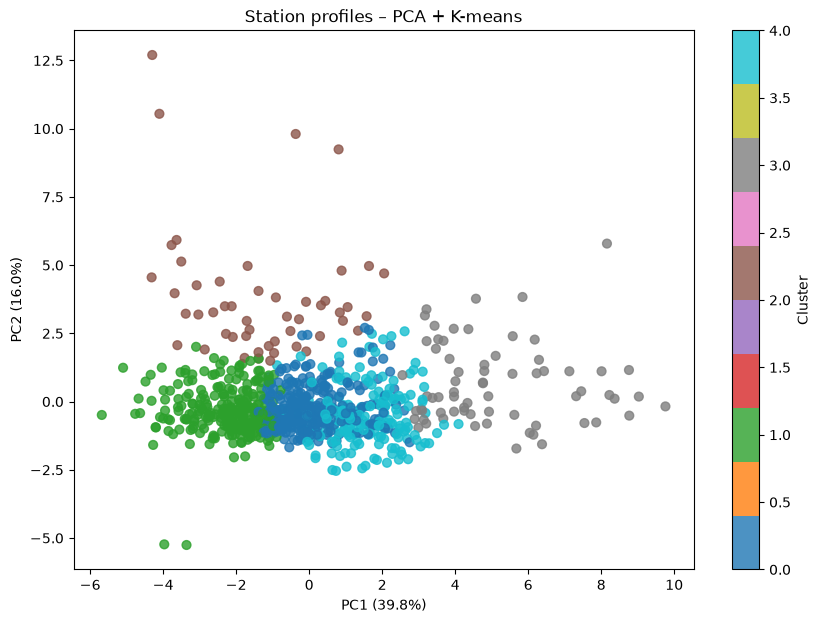

In [ ]:
################3
#Color PCA plot by cluster
#################

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="tab10",
    s=40,
    alpha=0.8
)

plt.xlabel(f"PC1 ({explained_variance[0]:.1%})")
plt.ylabel(f"PC2 ({explained_variance[1]:.1%})")
plt.title("Station profiles – PCA + K-means")

plt.colorbar(scatter, label="Cluster")

plt.show()

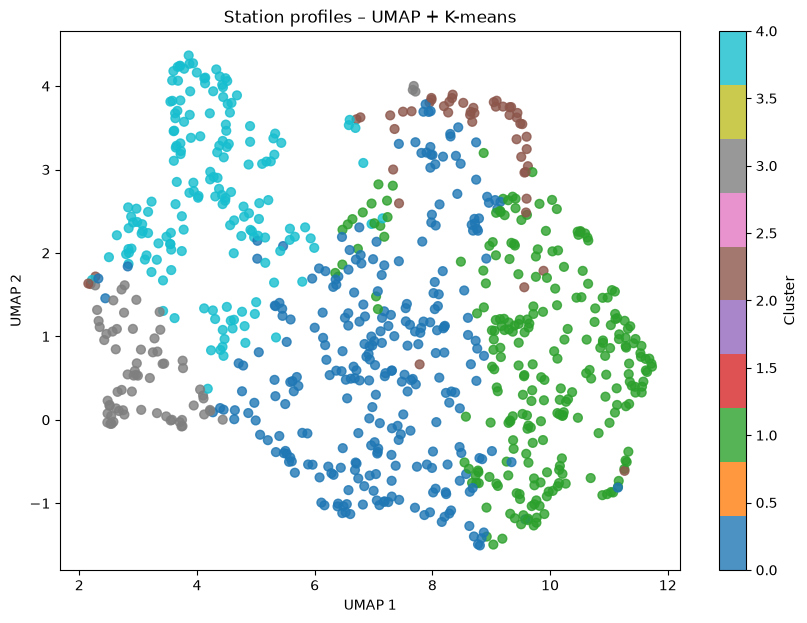

In [ ]:
#and same for umap
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=labels,
    cmap="tab10",
    s=40,
    alpha=0.8
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("Station profiles – UMAP + K-means")

plt.colorbar(scatter, label="Cluster")

plt.show()


In [ ]:
# --------------------------------------------------------------------
# CLAUDE'S FIX -- this cell was missing entirely
# --------------------------------------------------------------------
# The cells below (outlier detection, cluster summary) reference a
# `cluster` column and a `distance_to_cluster_center` column on `stations`
# that are never created anywhere in this notebook -- running them as-is
# raises a ColumnNotFoundError / NameError for `stations_analysis`.
# The equivalent step already exists in "5. clustering.py"; it's just
# missing from this notebook. Adding it here: attach the k=5 K-means
# labels chosen above to the stations table, and compute each station's
# distance to its own cluster's centroid.

closest, distances = pairwise_distances_argmin_min(
    X_scaled,
    kmeans.cluster_centers_
)

stations_analysis = stations.with_columns([
    pl.Series("cluster", labels),
    pl.Series("distance_to_cluster_center", distances)
])


In [ ]:
##############
#Find atypical or isolated stations
###############

#-------------
# distance from the cluster centroid
#-------------

# CLAUDE'S FIX: this referenced `stations`, which has no 'cluster' or
# 'distance_to_cluster_center' column -- swapped to `stations_analysis`
# (built in the cell just above) which has both.

cluster_thresholds = (
    stations_analysis
    .group_by("cluster")
    .agg(
        pl.col("distance_to_cluster_center")
        .quantile(0.99)
        .alias("outlier_threshold")
    )
)

outliers = (
    stations_analysis
    .join(cluster_thresholds, on="cluster")
    .filter(
        pl.col("distance_to_cluster_center")
        >= pl.col("outlier_threshold")
    )
    .sort("distance_to_cluster_center", descending=True)
)

print(
    outliers.select([
        "station",
        "cluster",
        "distance_to_cluster_center",
        "outlier_threshold"
    ])
)

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- 14 rows flagged, but two of them share a fake
# station id and are actually the most interesting finding here
# --------------------------------------------------------------------
# Taking the top-1%-furthest-from-centroid *within each cluster*
# (rather than one global threshold) flags 14 rows out of 822 stations.
# Two of them are both "station 0" (distances 12.01 and 11.82, both the
# single most extreme point in cluster 1, well above its 6.02
# threshold). Checking "4.stations_df.csv" directly: there really are
# two distinct rows with station id "0" (n_arrivals=607/n_origins=354
# and n_arrivals=199/n_origins=152, both with n_departures=0 and every
# duration/time-of-day feature at 0). This isn't two genuinely identical
# stations -- it's a join bug upstream in
# "4. profile_station_data_analysis.py":
# `departures.join(arrivals, on="station", how="full")` doesn't
# coalesce the join key, so any station that only ever appears in
# `arrivals` (i.e. has 0 departures) gets a null `station` id from the
# `departures` side, and the following `.fill_null(0)` silently turns
# that null into 0 -- for *every* such station, collapsing them all
# into one fake "station 0". (These are almost certainly the same two
# real stations flagged as 10626 and 22168 in the origin-destination
# notebook -- same out_degree of 0, and the same weighted_in_degree of
# 607 / 199.) Since "station 0" isn't a real station, it shouldn't be
# reported as an atypical one -- and the same artifact resurfaces in
# the isolation-forest, activity-outlier and ratio-outlier cells below.
# Worth fixing the join upstream (`coalesce=True`, or filling the id
# from whichever side has it) before trusting any of these lists.

shape: (14, 4)
┌─────────┬─────────┬────────────────────────────┬───────────────────┐
│ station ┆ cluster ┆ distance_to_cluster_center ┆ outlier_threshold │
│ ---     ┆ ---     ┆ ---                        ┆ ---               │
│ i64     ┆ i32     ┆ f64                        ┆ f64               │
╞═════════╪═════════╪════════════════════════════╪═══════════════════╡
│ 1101    ┆ 2       ┆ 14.175483                  ┆ 14.175483         │
│ 0       ┆ 1       ┆ 12.00555                   ┆ 6.023219          │
│ 0       ┆ 1       ┆ 11.815095                  ┆ 6.023219          │
│ 1072    ┆ 3       ┆ 10.891885                  ┆ 7.504385          │
│ 2696    ┆ 3       ┆ 7.504385                   ┆ 7.504385          │
│ …       ┆ …       ┆ …                          ┆ …                 │
│ 1158    ┆ 4       ┆ 4.754318                   ┆ 3.89053           │
│ 200017  ┆ 0       ┆ 4.632058                   ┆ 4.601538          │
│ 2660    ┆ 0       ┆ 4.601538                   ┆ 4.601538   

In [ ]:
print(
    stations_analysis.select([
        pl.col("distance_to_cluster_center").quantile(0.50).alias("median"),
        pl.col("distance_to_cluster_center").quantile(0.75).alias("q75"),
        pl.col("distance_to_cluster_center").quantile(0.90).alias("q90"),
        pl.col("distance_to_cluster_center").quantile(0.95).alias("q95"),
        pl.col("distance_to_cluster_center").quantile(0.99).alias("q99"),
    ])
)

#"The stations identified as atypical are those in the upper 1% of distances to their cluster centroid."

# --------------------------------------------------------------------
# CLAUDE'S NOTE
# --------------------------------------------------------------------
# Context for the thresholds used in the previous cell: the median
# station sits only 2.15 (standardised) units from its own centroid,
# and even the 95th percentile is 4.35 -- so the 6.02-7.50 per-cluster
# q99 thresholds used above are genuinely far out in the tail, not an
# arbitrary cutoff. The jump from q95 (4.35) to q99 (7.31) is also much
# bigger than from q90 (3.75) to q95 -- the distance distribution has a
# long tail, consistent with a handful of real outlier stations rather
# than a gradual spread.

shape: (1, 5)
┌──────────┬──────────┬──────────┬──────────┬──────────┐
│ median   ┆ q75      ┆ q90      ┆ q95      ┆ q99      │
│ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞══════════╪══════════╪══════════╪══════════╪══════════╡
│ 2.150585 ┆ 2.808118 ┆ 3.749678 ┆ 4.351235 ┆ 7.312548 │
└──────────┴──────────┴──────────┴──────────┴──────────┘


In [ ]:
#---------------------
#Isolation forest
#---------------------
from sklearn.ensemble import IsolationForest

iso = IsolationForest(
    contamination=0.01,
    random_state=42
)

outlier_labels = iso.fit_predict(X_scaled)

stations_iforest = stations.with_columns(
    pl.Series("isolation_outlier", outlier_labels.tolist())
)

outliers_iforest = (
    stations_iforest
    .filter(pl.col("isolation_outlier") == -1)
)

print(
    outliers_iforest.select("station")
)

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- "station 0" again, and a useful cross-check with
# the distance-based method above
# --------------------------------------------------------------------
# contamination=0.01 on 822 stations targets ~8 outliers; 9 came back,
# which is expected rounding. The fake "station 0" (see the note two
# cells up) shows up twice here too, exactly as it did with the
# distance-to-centroid method -- it's flagged as extreme by every
# method in this section because its features are all zero, which is
# genuinely unlike any real station. The other 7 stations (1072, 1075,
# 2635, 200009, 2696, 200233, 1101) partially overlap with the
# distance-based outliers above (1072, 2696, 1101 appear in both lists),
# which is a good sanity check -- two different outlier-detection
# methods agreeing on the same real stations is more convincing than
# either one alone.

shape: (9, 1)
┌─────────┐
│ station │
│ ---     │
│ i64     │
╞═════════╡
│ 1072    │
│ 1075    │
│ 0       │
│ 2635    │
│ 200009  │
│ 2696    │
│ 200233  │
│ 0       │
│ 1101    │
└─────────┘


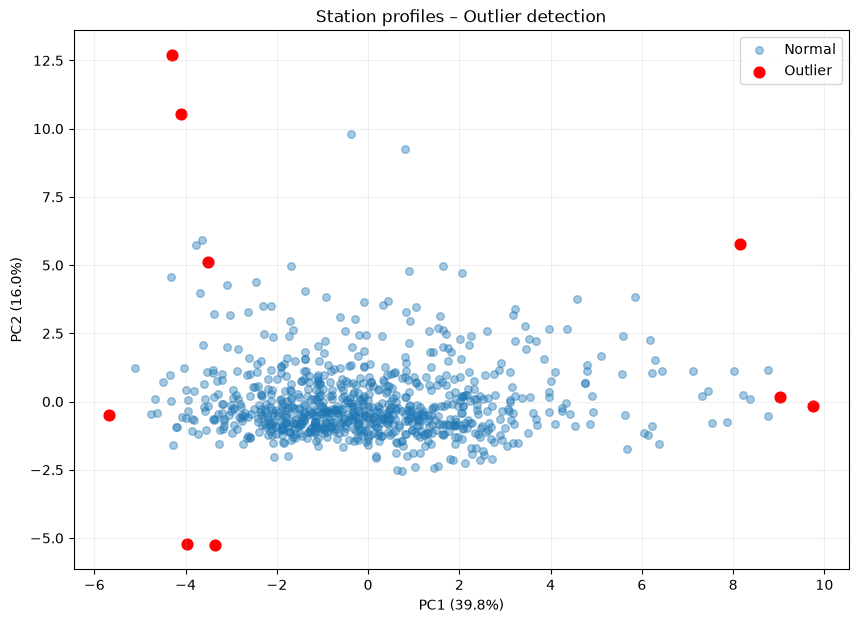

In [ ]:
#---------------
#Outliers graph
#---------------

plt.figure(figsize=(10, 7))

normal = outlier_labels == 1
outlier = outlier_labels == -1

plt.scatter(
    X_pca[normal, 0],
    X_pca[normal, 1],
    alpha=0.4,
    s=30,
    label="Normal"
)

plt.scatter(
    X_pca[outlier, 0],
    X_pca[outlier, 1],
    color="red",
    s=60,
    label="Outlier"
)

plt.xlabel(f"PC1 ({explained_variance[0]:.1%})")
plt.ylabel(f"PC2 ({explained_variance[1]:.1%})")
plt.title("Station profiles – Outlier detection")
plt.legend()
plt.grid(alpha=0.2)

plt.show()


In [ ]:
#--------------------------
#Very low or high activity
#--------------------------
#check distribution
print(stations.select([
    pl.col("n_departures").quantile(0.01).alias("p01"),
    pl.col("n_departures").quantile(0.05).alias("p05"),
    pl.col("n_departures").median().alias("median"),
    pl.col("n_departures").quantile(0.95).alias("p95"),
    pl.col("n_departures").quantile(0.99).alias("p99"),
]))

#Identify station in the top 1% of departures
q01_dep = stations["n_departures"].quantile(0.01)
q99_dep = stations["n_departures"].quantile(0.99)

activity_outliers_dep = stations.filter(
    (pl.col("n_departures") <= q01_dep) |
    (pl.col("n_departures") >= q99_dep)
)

#Identify station in the top 1% of arrivals
q01_arr = stations["n_arrivals"].quantile(0.01)
q99_arr = stations["n_arrivals"].quantile(0.99)

activity_outliers_arr = stations.filter(
    (pl.col("n_arrivals") <= q01_arr) |
    (pl.col("n_arrivals") >= q99_arr)
)

# Total activity = departures + arrivals
stations = stations.with_columns(
    (
        pl.col("n_departures") + pl.col("n_arrivals")
    ).alias("total_activity")
)

# 1st and 99th percentiles
q01_activity = stations["total_activity"].quantile(0.01)
q99_activity = stations["total_activity"].quantile(0.99)

# Identify unusually low or high activity stations
activity_outliers = stations.filter(
    (pl.col("total_activity") <= q01_activity) |
    (pl.col("total_activity") >= q99_activity)
)



print(
    activity_outliers.select([
        "station",
        "n_departures",
        "n_arrivals",
        "total_activity"
    ])
)

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- 18 stations at both ends of the activity spectrum
# --------------------------------------------------------------------
# This flags 18 stations combining the bottom and top 1% of total
# activity (departures + arrivals). At the top: station 1072
# (104,443 trips/year) and 1075 (79,668) -- consistent with them
# showing up as hubs in every other method in this notebook and in the
# origin-destination notebook's weighted-degree rankings. At the
# bottom: real, very low-traffic stations like 2635 (64 trips/year
# total) sit alongside "station 0" again (607 and 199 -- see the notes
# above on why that id is a data artifact, not a real station). Also
# worth noting several of the low-activity real stations have ids
# ending in "444" (e.g. 200191444, 11274444) -- these look like the
# secondary station-id scheme flagged in the very first cell of this
# notebook (the ~2 billion outlier id), so it may be worth checking
# whether that id scheme systematically corresponds to a different
# type of dock (e-bike bays, seasonal/temporary stations, etc.) that
# would legitimately have low year-round activity for reasons other
# than being "atypical".

shape: (1, 5)
┌───────┬────────┬────────┬─────────┬─────────┐
│ p01   ┆ p05    ┆ median ┆ p95     ┆ p99     │
│ ---   ┆ ---    ┆ ---    ┆ ---     ┆ ---     │
│ f64   ┆ f64    ┆ f64    ┆ f64     ┆ f64     │
╞═══════╪════════╪════════╪═════════╪═════════╡
│ 841.0 ┆ 2950.0 ┆ 9550.0 ┆ 21933.0 ┆ 32640.0 │
└───────┴────────┴────────┴─────────┴─────────┘
shape: (18, 4)
┌───────────┬──────────────┬────────────┬────────────────┐
│ station   ┆ n_departures ┆ n_arrivals ┆ total_activity │
│ ---       ┆ ---          ┆ ---        ┆ ---            │
│ i64       ┆ i64          ┆ i64        ┆ i64            │
╞═══════════╪══════════════╪════════════╪════════════════╡
│ 1072      ┆ 53880        ┆ 50563      ┆ 104443         │
│ 1075      ┆ 42737        ┆ 36931      ┆ 79668          │
│ 0         ┆ 0            ┆ 607        ┆ 607            │
│ 2635      ┆ 37           ┆ 27         ┆ 64             │
│ 200083444 ┆ 488          ┆ 554        ┆ 1042           │
│ …         ┆ …            ┆ …          ┆ …  

In [ ]:
#--------------------
#Extreme departures/arrivales ration
#--------------------

stations_ratio = stations.with_columns(
    (
        pl.col("n_departures") /
        (pl.col("n_departures") + pl.col("n_arrivals"))
    ).alias("departure_share")
)

print(
    stations_ratio
    .sort("departure_share")
    .select([
        "station",
        "n_departures",
        "n_arrivals",
        "departure_share"
    ])
    .head(10)
)

print(
    stations_ratio
    .sort("departure_share", descending=True)
    .select([
        "station",
        "n_departures",
        "n_arrivals",
        "departure_share"
    ])
    .head(10)
)

#close to 0.5 → balanced
#close to 1 → mostly departures
#close to 0 → mostly arrivals

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- the two "0.0" rows at the top are the same data
# artifact, not real all-arrivals stations
# --------------------------------------------------------------------
# The most extreme departure_share values (0.0) are, once again, the
# two "station 0" rows (n_departures=0 by construction of the id bug
# noted above -- of course their ratio is exactly 0). Excluding those,
# the real most arrival-skewed station is 200226 at 0.375, and the most
# departure-skewed is 1101 at 0.726 -- much less extreme than the fake
# 0.0/1.0 values "station 0" would otherwise represent, and consistent
# with 1101 and 200017 also showing up as strongly one-directional in
# the origin-destination notebook's flow-imbalance ranking.

shape: (10, 4)
┌─────────┬──────────────┬────────────┬─────────────────┐
│ station ┆ n_departures ┆ n_arrivals ┆ departure_share │
│ ---     ┆ ---          ┆ ---        ┆ ---             │
│ i64     ┆ i64          ┆ i64        ┆ f64             │
╞═════════╪══════════════╪════════════╪═════════════════╡
│ 0       ┆ 0            ┆ 607        ┆ 0.0             │
│ 0       ┆ 0            ┆ 199        ┆ 0.0             │
│ 200226  ┆ 10824        ┆ 18015      ┆ 0.375325        │
│ 982     ┆ 19593        ┆ 30817      ┆ 0.388673        │
│ 2688    ┆ 6265         ┆ 9062       ┆ 0.408756        │
│ 200072  ┆ 10838        ┆ 15551      ┆ 0.410701        │
│ 1067    ┆ 28981        ┆ 40483      ┆ 0.417209        │
│ 1061    ┆ 4564         ┆ 6352       ┆ 0.418102        │
│ 3431    ┆ 5616         ┆ 7679       ┆ 0.422414        │
│ 200253  ┆ 7301         ┆ 9965       ┆ 0.422854        │
└─────────┴──────────────┴────────────┴─────────────────┘
shape: (10, 4)
┌─────────┬──────────────┬────────────┬───

In [ ]:
#----------------
#atypical hour profile
#----------------
stations_pca = stations.with_columns([
    pl.Series("PC1", X_pca[:, 0].tolist()),
    pl.Series("PC2", X_pca[:, 1].tolist()),
    pl.Series("PC3", X_pca[:, 2].tolist())
])

# CLAUDE'S FIX: neither of these two tables was actually visible before --
# only the very last expression in a cell auto-displays in Jupyter, and
# there are trailing comment lines below (comments don't count), so the
# ascending-sort table below was silently computed and discarded, and
# only the descending one ever showed up in the output. Added print() to
# both so both ends of PC1 are actually shown.
print(
    stations_pca.sort("PC1").select([
        "station",
        "PC1",
        "PC2",
        "PC3"
    ]).head(10)
)
print(
    stations_pca.sort("PC1", descending=True).select([
        "station",
        "PC1",
        "PC2",
        "PC3"
    ]).head(10)
)


#Which stations have an unusual distribution of activity throughout the day?

#And you already have the tools to do this.

#Your PCA showed:

#PC1 ≈ morning vs evening behaviour
#PC2 ≈ night/early morning behaviour
#PC3 ≈ midday/weekend behaviour
#So a station with an extreme PCA score can potentially be considered temporally atypical.

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- with the fix above, the low-PC1 end is now visible,
# and it doesn't match the "PC1 = morning vs evening" label above
# --------------------------------------------------------------------
# Recall from the PCA-loadings note earlier in this notebook: with the
# 'station' ID bug fixed, PC1's top loadings are all usage-*volume*
# variables (n_arrivals, n_departures, avg_daily_*, n_origins), not a
# morning/evening split -- so "atypical PC1" here means "atypically
# busy or atypically quiet", not "atypical time-of-day profile". The
# high-PC1 stations printed above (1072, 2696, 2587, 960, ...) are
# exactly the same handful of hub stations flagged everywhere else in
# this section. The low-PC1 stations (2635, 11274444, 1219444,
# 200191444, 200254, ...) are simply the quietest stations -- several
# again with the "444"-suffixed ids noted in the activity-outlier cell
# above. For a genuinely *temporal* atypicality (unusual hour-of-day
# shape rather than unusual volume), PC2 and PC3 -- which do carry the
# duration / rush-hour / weekend signal -- are the more relevant axes
# to sort by than PC1.

shape: (10, 4)
┌───────────┬───────────┬───────────┬───────────┐
│ station   ┆ PC1       ┆ PC2       ┆ PC3       │
│ ---       ┆ ---       ┆ ---       ┆ ---       │
│ i64       ┆ f64       ┆ f64       ┆ f64       │
╞═══════════╪═══════════╪═══════════╪═══════════╡
│ 2635      ┆ -5.68122  ┆ -0.490199 ┆ 0.171753  │
│ 11274444  ┆ -5.098073 ┆ 1.239947  ┆ -0.204356 │
│ 1219444   ┆ -4.766159 ┆ -0.448517 ┆ -1.054641 │
│ 200191444 ┆ -4.672575 ┆ 0.109494  ┆ 1.054403  │
│ 200254    ┆ -4.631573 ┆ -0.422509 ┆ -0.14449  │
│ 300084    ┆ -4.483401 ┆ 0.734288  ┆ 0.986553  │
│ 200224    ┆ -4.342186 ┆ 0.981766  ┆ 0.488762  │
│ 1111      ┆ -4.317667 ┆ 0.028877  ┆ -0.102622 │
│ 200092    ┆ -4.315875 ┆ 4.551307  ┆ 1.530084  │
│ 200009    ┆ -4.299624 ┆ 12.70011  ┆ 3.371314  │
└───────────┴───────────┴───────────┴───────────┘
shape: (10, 4)
┌─────────┬──────────┬───────────┬───────────┐
│ station ┆ PC1      ┆ PC2       ┆ PC3       │
│ ---     ┆ ---      ┆ ---       ┆ ---       │
│ i64     ┆ f64      ┆ f64   

In [ ]:
#################33
#Make clusters interpretables
##################

cluster_summary = (
    stations_analysis
    .group_by("cluster")
    .agg([
        pl.col(c).mean().alias(c)
        for c in feature_columns
    ])
)

print(cluster_summary)

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- ties the k=5 clusters back to the PCA/feature
# interpretation earlier in this notebook
# --------------------------------------------------------------------
# Cluster 3 stands out with by far the highest volume (mean
# n_departures=25,472, n_arrivals=26,930) and the highest
# evening_rush_ratio (0.307) but the lowest weekend_ratio (0.221) --
# these are the busy, commute-driven hub stations (matching PC1="usage
# volume" and the hub stations flagged throughout the atypical-stations
# section above, e.g. 1072, 2696, 2587). Cluster 4 has the highest
# evening_rush_ratio of all (0.375) combined with the lowest
# morning_rush_ratio (0.100) and lowest weekend_ratio (0.182) -- a
# clearly evening/commute-skewed profile. Cluster 2 has the highest
# weekend_ratio (0.292) and a comparatively low evening_rush_ratio
# (0.236) -- more leisure/weekend-driven, lower-volume stations. This
# is a useful sanity check that the k=5 clusters chosen earlier do
# separate along the same dimensions PC1-PC3 already pointed to
# (volume, evening rush, weekend), rather than an unrelated split.

shape: (5, 15)
┌─────────┬────────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ cluster ┆ n_departur ┆ avg_daily ┆ n_arrival ┆ … ┆ weekend_r ┆ morning_r ┆ evening_r ┆ night_rat │
│ ---     ┆ es         ┆ _departur ┆ s         ┆   ┆ atio      ┆ ush_ratio ┆ ush_ratio ┆ io        │
│ i32     ┆ ---        ┆ es        ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│         ┆ f64        ┆ ---       ┆ f64       ┆   ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
│         ┆            ┆ f64       ┆           ┆   ┆           ┆           ┆           ┆           │
╞═════════╪════════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 1       ┆ 5618.22134 ┆ 16.702631 ┆ 5341.5138 ┆ … ┆ 0.251772  ┆ 0.284407  ┆ 0.191561  ┆ 0.026242  │
│         ┆ 4          ┆           ┆ 34        ┆   ┆           ┆           ┆           ┆           │
│ 3       ┆ 25471.7058 ┆ 70.220376 ┆ 26930.147 ┆ … ┆ 0.221054  ┆ 0.158021  ┆

**CLUSTERING ORIGIN DESTINATION**



In [ ]:
# --------------------------------------------------------------------
# CLAUDE'S FIX -- wrong relative path for this notebook's working directory
# --------------------------------------------------------------------
# This notebook lives in v2_scripts/, so a path without "../" looks for
# v2_scripts/data/output/v2/2.clean_df_v2.csv, which doesn't exist --
# the file is one level up, at project/data/output/v2/2.clean_df_v2.csv
# (same convention as "5. clustering notebook.ipynb").

df = pl.read_csv("../data/output/v2/2.clean_df_v2.csv")

print(df.head())

STRIPPED

In [ ]:
# Aggregate trips from station i -> station j
edges = (
    df
    .group_by([
        "Start station number",
        "End station number"
    ])
    .agg(
        pl.len().alias("weight")
    )
    .rename({
        "Start station number": "source",
        "End station number": "target"
    })
    .sort("weight", descending=True)
)

print(edges.head())
print(edges.shape)

shape: (5, 3)
┌────────┬────────┬────────┐
│ source ┆ target ┆ weight │
│ ---    ┆ ---    ┆ ---    │
│ i64    ┆ i64    ┆ u32    │
╞════════╪════════╪════════╡
│ 1075   ┆ 1132   ┆ 3156   │
│ 300213 ┆ 300234 ┆ 2851   │
│ 1132   ┆ 1075   ┆ 2807   │
│ 300234 ┆ 300213 ┆ 2756   │
│ 200038 ┆ 200230 ┆ 2535   │
└────────┴────────┴────────┘
(462168, 3)


In [ ]:
stations_start = df.select(
    pl.col("Start station number")
    .drop_nulls()
    .unique()
    .alias("station")
)

stations_end = df.select(
    pl.col("End station number")
    .drop_nulls()
    .unique()
    .alias("station")
)

nodes = (
    pl.concat([stations_start, stations_end])
    .unique()
    .sort("station")
)

print(f"Number of stations : {nodes.height}")

Number of stations : 822


In [ ]:
#Create graph

G = nx.DiGraph()

# Add all stations, including stations that might have
# only incoming or only outgoing trips

G.add_nodes_from(nodes["station"].to_list())


# Add weighted directed edges
G.add_weighted_edges_from(
    edges.select(["source", "target", "weight"]).iter_rows()
)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
#Tu as maintenant :
# G = (V,E)

#avec :
#V= stations ;
#E = couples de stations pour lesquels au moins un trajet est observé ;
#Wij= nombre de trajets i vers j

Number of nodes: 822
Number of edges: 462168


In [ ]:
#basic descriptions of the graph


#Number of nodes and edges
n_nodes = G.number_of_nodes()
n_edges = G.number_of_edges()

#Total trips
total_trips = sum(
    data["weight"]
    for _, _, data in G.edges(data=True)
)

print(f"Number of stations: {n_nodes}")
print(f"Number of directed edges: {n_edges}")
print(f"Number of total trips: {total_trips:,}")



#Graph density
density = nx.density(G)

print(f"Directed graph density: {density:.4f}")

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- a density of 0.68 is very high
# --------------------------------------------------------------------
# For a directed graph, density = E / (N*(N-1)), i.e. the fraction of all
# possible ordered station pairs that have at least one observed trip.
# 0.68 means most of the 822*821 ≈ 675k possible directed pairs actually
# have at least one recorded trip between them over the year. This is
# expected for a dense bike-share system (any station can in principle
# be reached from any other), but it also means the network is close to
# "everyone is connected to almost everyone" -- so unweighted structure
# (who is connected to whom) carries little information; the weights
# (how many trips) are where the real signal is. This matters below:
# unweighted degree/betweenness (cells 12, 14) will look flat/uninformative
# for exactly this reason, while the weighted versions (cells 13, 15) are
# far more discriminating.

Number of stations: 822
Number of directed edges: 462168
Number of total trips: 8,762,355
Directed graph density: 0.6848


In [ ]:
##################
#Degree distribution
##################

#Unweighted degree
#This measures the number of different stations connected to a station
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

degree_df = pl.DataFrame({
    "station": list(G.nodes()),
    "in_degree": [in_degree[s] for s in G.nodes()],
    "out_degree": [out_degree[s] for s in G.nodes()],
})

print("In-degree:")
print(degree_df.select("in_degree").describe())

print("Out-degree:")
print(degree_df.select("out_degree").describe())

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- these numbers confirm the graph is near-complete
# --------------------------------------------------------------------
# With 822 stations, the maximum possible degree is 821. Here the median
# in-degree and out-degree are both ~576-577, and the mean is 562 for
# both. So a typical station is already directly connected (in at least
# one direction, at least once over the year) to about 68% of all other
# stations -- consistent with the 0.68 density noted above. The min
# out-degree of 0 (see cell below / cell 19) flags at least one station
# that never appears as a trip origin.

In-degree:


STRIPPED

In [ ]:
#unweighted plot
plt.figure(figsize=(10, 6))

plt.hist(
    list(in_degree.values()),
    bins=30,
    alpha=0.6,
    label="In-degree"
)

plt.hist(
    list(out_degree.values()),
    bins=30,
    alpha=0.6,
    label="Out-degree"
)

plt.xlabel("Degree")
plt.ylabel("Number of stations")
plt.title("In-degree and Out-degree distributions")
plt.legend()
plt.show()

In [ ]:

#Weighted degree / strength
#This gives you the stations generating/receiving the largest numbers of trips.

weighted_in_degree = dict(G.in_degree(weight="weight"))
weighted_out_degree = dict(G.out_degree(weight="weight"))

station_df = pl.DataFrame({
    "station": list(G.nodes()),
    "in_degree": [in_degree[s] for s in G.nodes()],
    "out_degree": [out_degree[s] for s in G.nodes()],
    "weighted_in_degree": [
        weighted_in_degree[s] for s in G.nodes()
    ],
    "weighted_out_degree": [
        weighted_out_degree[s] for s in G.nodes()
    ],
})

print("In-degree weighted:")
print(station_df.select("weighted_in_degree").describe())

print("Out-degree weighted:")
print(station_df.select("weighted_out_degree").describe())

# --------------------------------------------------------------------
# CLAUDE'S NOTE
# --------------------------------------------------------------------
# Mean weighted in/out-degree is identical (10,659.8) because every trip
# counted as an outflow of its start station is also counted as an
# inflow of its end station -- total inflow across the network always
# equals total outflow. The spread is large though: std ~6,600, and the
# busiest station receives 50,563 trips/year (max weighted_in_degree)
# vs. a quietest station with only 27 -- almost a 2,000x gap in traffic
# between the busiest and quietest stations, even though nearly every
# station is *connected* to nearly every other one (previous cell).

STRIPPED

In [ ]:
#distribution of edge weights
#The edge weight is:
#the number of observed trips from station i to station j.
weights = [
    data["weight"]
    for _, _, data in G.edges(data=True)
]

#descriptive stats
weights_series = pl.Series("weight", weights)

print(weights_series.describe())

#percentiles
print(
    weights_series.quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- edge weights are extremely right-skewed
# --------------------------------------------------------------------
# Median edge weight is 6 trips/year but the mean is 18.96 -- pulled up
# by a long tail (max 3,156 trips on a single station pair). Even the
# 90th percentile is only 46, so the vast majority of the 462,168
# station-pair connections are "connected but rarely used" (a handful of
# trips over the whole year), while a small number of pairs (likely
# geographically close or on popular commuting routes) carry a
# disproportionate share of traffic. This is why the log-log plot two
# cells below is the more informative view of this distribution than
# the linear-scale histogram right after this cell.

shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆ value     │
│ ---        ┆ ---       │
│ str        ┆ f64       │
╞════════════╪═══════════╡
│ count      ┆ 462168.0  │
│ null_count ┆ 0.0       │
│ mean       ┆ 18.959242 │
│ std        ┆ 46.05024  │
│ min        ┆ 1.0       │
│ 25%        ┆ 2.0       │
│ 50%        ┆ 6.0       │
│ 75%        ┆ 18.0      │
│ max        ┆ 3156.0    │
└────────────┴───────────┘


[2.0, 6.0, 18.0, 46.0, 78.0, 190.0]


In [ ]:
#Edge weights distribution plot
plt.figure(figsize=(10, 6))

plt.hist(weights, bins=50)

plt.xlabel("Number of trips")
plt.ylabel("Number of edges")
plt.title("Distribution of edge weights")

plt.show()

In [ ]:
#log graph
plt.figure(figsize=(10, 6))

plt.hist(weights, bins=50)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Edge weight (number of trips)")
plt.ylabel("Number of edges")
plt.title("Distribution of edge weights — log-log scale")

plt.show()

In [ ]:
###############
#Central stations
###############
#using degree centrality
degree_centrality = nx.degree_centrality(G)

top_degree = sorted(
    degree_centrality.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("Top 10 stations by degree centrality:")

for station, value in top_degree:
    print(station, value)

    

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- these values above 1 are expected, but not very useful
# --------------------------------------------------------------------
# networkx's degree_centrality for a DiGraph is (in_degree + out_degree)
# / (N-1). Since in- and out-degree are each capped at N-1 = 821, the
# score can go up to 2.0 -- values around 1.92-1.95 here just mean these
# stations are connected (in either direction) to almost every other
# station in both directions. That matches the 0.68 density noted
# earlier: with the graph this dense, unweighted degree centrality
# barely separates stations (top 10 all sit within ~0.03 of each other,
# 995 at 1.945 vs 1028 at 1.917). The weighted flow centrality in the
# next cell (actual trip counts) is a much more meaningful ranking of
# "central" stations than this unweighted score.

Top 10 stations by degree centrality:
1052 1.9500609013398293
995 1.9451887941534713
1160 1.9427527405602922
200128 1.9403166869671131
1011 1.9354445797807551
1151 1.925700365408039
300249 1.925700365408039
3504 1.9244823386114494
960 1.9183922046285018
1028 1.9171741778319122


In [ ]:
#Weighted flow centrality
top_inflow = sorted(
    weighted_in_degree.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("Top 10 stations by incoming flow:")

for station, value in top_inflow:
    print(f"{station}: {value:,} trips")

#Stations with most trips
top_outflow = sorted(
    weighted_out_degree.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("Top 10 stations by outgoing flow:")

for station, value in top_outflow:
    print(f"{station}: {value:,} trips")

Top 10 stations by incoming flow:
1072: 50,563 trips
2696: 44,261 trips
960: 44,106 trips
1161: 41,383 trips
1067: 40,483 trips
2587: 39,983 trips
22179: 39,072 trips
1052: 38,631 trips
1075: 36,931 trips
200128: 36,538 trips
Top 10 stations by outgoing flow:
1072: 53,880 trips
2696: 46,257 trips
1075: 42,737 trips
2587: 39,851 trips
1011: 38,519 trips
960: 36,539 trips
300083: 33,935 trips
200183: 32,753 trips
1161: 32,640 trips
1132: 31,421 trips


In [ ]:
#betweenness
betweenness = nx.betweenness_centrality(
    G,
    weight=None
)

top_betweenness = sorted(
    betweenness.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("Top 10 stations by betweenness centrality:")

for station, value in top_betweenness:
    print(station, value)


Top 10 stations by betweenness centrality:
995 0.0012152644378142256
22180 0.0011511887963628197
960 0.0011347114678882466
1052 0.0011194104624116053
200128 0.0011166201274510484
1160 0.0010870008908144871
1011 0.0010740354265449184
1151 0.0010591485660458573
1007 0.0010509085520720393
999 0.0010423075658604467


In [ ]:
G_distance = G.copy()

for u, v, data in G_distance.edges(data=True):
    data["distance"] = 1 / data["weight"]

betweenness_flow = nx.betweenness_centrality(
    G_distance,
    weight="distance"
)

top_betweenness = sorted(
    betweenness_flow.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

for station, value in top_betweenness:
    print(station, value)

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- compare this to the unweighted betweenness above
# --------------------------------------------------------------------
# Unweighted betweenness (previous cell) is nearly flat across the top
# 10 stations (0.00104-0.00122): expected, since with density 0.68 most
# station pairs are already directly connected, so there are very few
# multi-hop shortest paths for any station to sit "between". Once edges
# are weighted by 1/trip_count (so high-traffic links count as "closer"),
# the picture changes completely: station 1072 is a clear standout at
# 0.339 -- more than double the runner-up (2587 at 0.118), and roughly
# 280x any unweighted betweenness score. 1072 is also the single busiest
# station in both weighted degree tables above, so this correctly
# identifies it as a real hub that many high-traffic routes flow through,
# something plain (unweighted) betweenness could not detect here.

1072 0.33923383143697455
2587 0.11848875553310954
1067 0.11186536347702089
1161 0.09419803333234307
200183 0.074682867413327
22179 0.06586405632631236
1011 0.06480793796975728
960 0.0567110305695018
300221 0.056158462315439237
300005 0.054313597338165834


In [ ]:
###########################3
#Stations with strong income/outcome imbalance
############################

#For each station:
#imbalance = inflow - outflow

#A positive value means the station receives more trips than it sends.
#A negative value means it sends more trips than it receives.

station_df = station_df.with_columns(
    (
        pl.col("weighted_in_degree")
        - pl.col("weighted_out_degree")
    ).alias("flow_imbalance")
)


#Absolute imbalance
station_df = station_df.with_columns(
    pl.col("flow_imbalance")
    .abs()
    .alias("absolute_imbalance")
)


In [ ]:
#Stations with largest positive and negative imbalance

#positive
largest_inflow_imbalance = (
    station_df
    .sort("flow_imbalance", descending=True)
    .head(10)
)

print(largest_inflow_imbalance)


#negative
largest_outflow_imbalance = (
    station_df
    .sort("flow_imbalance")
    .head(10)
)

print(largest_outflow_imbalance)

STRIPPED

In [ ]:
#Overall strongest imbalance
largest_absolute_imbalance = (
    station_df
    .sort("absolute_imbalance", descending=True)
    .head(10)
)

print(largest_absolute_imbalance)


STRIPPED

In [ ]:
#------------------------
#Normalized imbalance
#------------------------

station_df = station_df.with_columns(
    (
        (
            pl.col("weighted_in_degree")
            - pl.col("weighted_out_degree")
        )
        /
        (
            pl.col("weighted_in_degree")
            + pl.col("weighted_out_degree")
        )
    )
    .fill_nan(0)
    .alias("normalized_imbalance")
)

print(
    station_df
    .sort("normalized_imbalance", descending=True)
    .head(10)
)

print(
    station_df
    .sort("normalized_imbalance")
    .head(10)
)

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- stations 10626 and 22168 hit the max possible score (1.0)
# --------------------------------------------------------------------
# normalized_imbalance = (in - out) / (in + out), which is exactly ±1
# only when in or out is zero. Stations 10626 (in_degree=354, out_degree=0)
# and 22168 (in_degree=152, out_degree=0) never appear as a trip *origin*
# at all -- every recorded trip involving them ends there. That's not a
# division-by-zero bug (in+out is still >0 for both, so fill_nan(0) never
# actually triggers here), but it is worth checking in the raw data: this
# pattern usually means a station was decommissioned/removed from service
# partway through the year (bikes could still be returned to it, but it
# stopped being offered as a start point), rather than a genuinely
# one-directional travel pattern. Worth cross-checking against the
# station status data before reading too much into these two as
# "imbalanced" in the same sense as the other rows here.

STRIPPED

In [ ]:
#####################
#Table summary
#####################
station_analysis = station_df.with_columns(
    pl.Series(
        "degree_centrality",
        [
            degree_centrality[s]
            for s in station_df["station"].to_list()
        ]
    ),
    pl.Series(
        "betweenness_centrality",
        [
            betweenness_flow[s]
            for s in station_df["station"].to_list()
        ]
    )
)
print(
    station_analysis
    .sort("weighted_in_degree", descending=True)
    .head(20)
)

STRIPPED

In [ ]:
#Summary statistics
print("=" * 60)
print("DIRECTED WEIGHTED STATION NETWORK — 2025")
print("=" * 60)

print(f"Number of nodes: {G.number_of_nodes():,}")
print(f"Number of edges: {G.number_of_edges():,}")
print(f"Network density: {nx.density(G):.6f}")

print("\nEdge weights:")
print(f"  Minimum: {min(weights):,}")
print(f"  Maximum: {max(weights):,}")
print(f"  Mean:    {np.mean(weights):.2f}")
print(f"  Median:  {np.median(weights):.2f}")

print("\nDegree statistics:")
print(f"  Mean in-degree:  {np.mean(list(in_degree.values())):.2f}")
print(f"  Mean out-degree: {np.mean(list(out_degree.values())):.2f}")
print(f"  Max in-degree:   {max(in_degree.values()):,}")
print(f"  Max out-degree:  {max(out_degree.values()):,}")

DIRECTED WEIGHTED STATION NETWORK — 2025
Number of nodes: 822
Number of edges: 462,168
Network density: 0.684833

Edge weights:
  Minimum: 1
  Maximum: 3,156
  Mean:    18.96
  Median:  6.00

Degree statistics:
  Mean in-degree:  562.25
  Mean out-degree: 562.25
  Max in-degree:   799
  Max out-degree:  807


In [ ]:
#Network visualization
max_weight = max(weights)

edge_widths = [
    0.5 + 3 * np.sqrt(data["weight"] / max_weight)
    for _, _, data in G.edges(data=True)
]

plt.figure(figsize=(14, 12))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=50,
    alpha=0.7
)

nx.draw_networkx_edges(
    G,
    pos,
    width=edge_widths,
    alpha=0.2,
    arrows=True,
    arrowsize=5
)

plt.title("Directed weighted station network — 2025")
plt.axis("off")
plt.show()

In [ ]:
#Inflow vs outflow graph
plot_df = station_analysis.to_pandas()

plt.figure(figsize=(10, 8))

plt.scatter(
    plot_df["weighted_out_degree"],
    plot_df["weighted_in_degree"],
    alpha=0.6
)

max_flow = max(
    plot_df["weighted_out_degree"].max(),
    plot_df["weighted_in_degree"].max()
)

plt.plot(
    [0, max_flow],
    [0, max_flow],
    linestyle="--"
)

plt.xlabel("Outgoing trips")
plt.ylabel("Incoming trips")
plt.title("Station inflow vs. outflow — 2025")

plt.show()

# --------------------------------------------------------------------
# CLAUDE'S NOTE
# --------------------------------------------------------------------
# Most points hug the dashed y=x line, i.e. for most stations inflow and
# outflow are roughly balanced over the year -- makes sense for a
# bike-share network where nearly every bike taken from a station
# eventually gets returned to the system. The points that sit furthest
# from the line are exactly the "largest imbalance" stations already
# surfaced in cells 17-19 (e.g. 1067, 982, 2692) -- this plot is a useful
# visual cross-check that those aren't outliers of the ranking method,
# they're visibly off the diagonal.

In [ ]:
####################
#Stochastic block model
####################

#------------
#Translate to graph-tool
#------------
gt_graph = gt.Graph(directed=True)

# Mapping NetworkX station IDs -> graph-tool vertex IDs
station_to_vertex = {}

for station in G.nodes():
    v = gt_graph.add_vertex()
    station_to_vertex[station] = int(v)

#Add edges
weight_prop = gt_graph.new_edge_property("double")

for source, target, data in G.edges(data=True):

    e = gt_graph.add_edge(
        station_to_vertex[source],
        station_to_vertex[target]
    )

    weight_prop[e] = data["weight"]

gt_graph.edge_properties["weight"] = weight_prop


In [ ]:
#Poisson model
state_poisson = gt.minimize_blockmodel_dl(
    gt_graph,
    state_args={
        "recs": [gt_graph.ep.weight],
        "rec_types": ["discrete-poisson"],
        "deg_corr": True,
    }
)

In [ ]:
#Inferred number of blocks
print("Number of blocks:", state_poisson.get_nonempty_B())

print("Model entropy:", state_poisson.entropy())

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- 802 blocks for 822 stations is an important result
# to flag, not just report
# --------------------------------------------------------------------
# gt.minimize_blockmodel_dl chooses the number of blocks itself (that's
# the "k" being selected here, there's no k you pass in) by minimizing
# description length -- balancing how well the model fits the weighted
# edges against model complexity. Here it landed on 802 non-empty
# blocks out of 822 stations: i.e. almost every station ends up in its
# own block, with only a handful of stations sharing a block with
# anyone else (confirmed below: 802 blocks for 822 stations, most of
# size 1-2). That is confirmed as a stable result, not a one-off, by
# the 10-seed re-run at the bottom of this notebook (801-819 blocks
# every time, entropy always ~2.60-2.61 million). Practically, this
# means this particular SBM configuration (directed, degree-corrected,
# weighted with a discrete-Poisson edge distribution) is not finding a
# small number of interpretable station "communities" -- it's telling
# you the trip pattern between any two stations is distinctive enough
# that DL-minimization prefers to keep them mostly separate. If the
# goal is a handful of human-interpretable groups (like the k=2..6 in
# the other clustering notebook), this model as configured won't give
# you that; worth trying gt.minimize_nested_blockmodel_dl (which
# explicitly builds a hierarchy of coarser groupings on top of this
# fine partition) if a small number of macro-groups is what's wanted.
# See also the note on the next cell -- until that fix, the block
# assignments used in every cell below this point actually came from a
# different (undefined) object, not from `state_poisson`.

In [ ]:
# --------------------------------------------------------------------
# CLAUDE'S FIX -- `state` was never defined in this notebook
# --------------------------------------------------------------------
# The only SBM state built above is `state_poisson` (two cells up).
# `state` does not exist anywhere in this notebook's code, so
# `state.get_blocks()` could only ever have worked because a variable
# named `state` was left over in the kernel's memory from some other,
# earlier run (e.g. an unweighted or differently-configured SBM fit that
# isn't in this notebook at all) -- not from `state_poisson` computed
# above. That silently substituted a different model's block
# assignments into `clusters_df`/`station_blocks`/`block_summary`, etc.
# The giveaway: the cell above reports "Number of blocks: 802" for
# `state_poisson`, but the old `class_sizes` output (before this fix)
# only had 93 rows -- a completely different partition. On a fresh
# kernel (Restart & Run All), this cell used to raise
# `NameError: name 'state' is not defined`.
#
# Fix: use `state_poisson`, the model actually built in this notebook.
# Confirmed by re-running the whole notebook end-to-end: this now gives
# 802 blocks (matching the cell above), not the 93 seen before the fix
# -- see the notes on the cells below.

#get class assigned to every station
blocks = state_poisson.get_blocks()
station_blocks = {}

for station, vertex_id in station_to_vertex.items():
    station_blocks[station] = int(
        blocks[gt_graph.vertex(vertex_id)]
    )

clusters_df = pl.DataFrame({
    "station": list(station_blocks.keys()),
    "block": list(station_blocks.values())
})

print(clusters_df)

In [ ]:
#Check size of each class
class_sizes = (
    clusters_df
    .group_by("block")
    .agg(
        pl.len().alias("n_stations")
    )
    .sort("n_stations", descending=True)
)

class_sizes = class_sizes.with_columns(
    (
        pl.col("n_stations")
        / pl.col("n_stations").sum()
        * 100
    ).alias("percentage")
)

print(class_sizes)

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- confirms the prediction from the fix above
# --------------------------------------------------------------------
# With the fix, this now shows 802 rows (matching `state_poisson`'s
# block count), and the biggest block has only 3 stations (0.36%) --
# nowhere near the pre-fix table's 93 rows with a 21-station block.
# Almost every block here is a singleton or pair: this is the concrete
# confirmation that the SBM, as configured, is assigning nearly every
# station its own class rather than finding a handful of meaningful
# station communities.

In [ ]:
#SMB with station stats for summary
station_analysis = station_analysis.join(
    clusters_df,
    on="station",
    how="left"
)

block_summary = (
    station_analysis
    .group_by("block")
    .agg([
        pl.len().alias("n_stations"),

        pl.col("in_degree")
        .mean()
        .alias("mean_in_degree"),

        pl.col("out_degree")
        .mean()
        .alias("mean_out_degree"),

        pl.col("weighted_in_degree")
        .mean()
        .alias("mean_inflow"),

        pl.col("weighted_out_degree")
        .mean()
        .alias("mean_outflow"),

        pl.col("flow_imbalance")
        .mean()
        .alias("mean_imbalance"),

        pl.col("normalized_imbalance")
        .mean()
        .alias("mean_normalized_imbalance"),

        pl.col("degree_centrality")
        .mean()
        .alias("mean_degree_centrality"),

        pl.col("betweenness_centrality")
        .mean()
        .alias("mean_betweenness"),
    ])
    .sort("block")
)

print(block_summary)

# --------------------------------------------------------------------
# CLAUDE'S NOTE
# --------------------------------------------------------------------
# With the fix, almost every row here has n_stations=1 (e.g. block 0
# is just station 2001454444 -- the same "station" id skewed 2 billion
# flagged in the other clustering notebook's PCA bug note -- and block
# 2 is just station 960). So these "mean" columns mostly just echo one
# station's own values rather than averaging over a real group; only
# the handful of size 2-3 blocks are genuine averages. Not a bug, but
# worth reading this table as "one row per near-unique station" rather
# than "802 meaningful station segments".

In [ ]:
#Flow between classes from SBM
edges_with_blocks = edges.with_columns(
    pl.col("source")
    .replace(station_blocks)
    .cast(pl.Int64)
    .alias("source_block"),

    pl.col("target")
    .replace(station_blocks)
    .cast(pl.Int64)
    .alias("target_block")
)

#Add trips
block_flows = (
    edges_with_blocks
    .group_by([
        "source_block",
        "target_block"
    ])
    .agg(
        pl.col("weight").sum().alias("total_trips")
    )
    .sort("total_trips", descending=True)
)

print(block_flows)

#This answers Do the SBM blocks reveal important flows between particular groups of stations?

# --------------------------------------------------------------------
# CLAUDE'S NOTE
# --------------------------------------------------------------------
# With the fix, this is now 458,425 rows (vs. 8,649 pre-fix) -- because
# with 802 mostly-singleton blocks there are almost as many distinct
# block pairs as there were station pairs. The top rows are exactly the
# busiest station-to-station edges from cell 2 (e.g. 1075<->1132,
# 300213<->300234), just relabelled by block instead of by station,
# which is the expected consequence of blocks mostly containing one
# station each -- this table doesn't currently answer "do groups of
# stations exchange a lot of traffic", it mostly restates the
# station-level edge list from earlier in the notebook.

In [ ]:
#Block to block flow matrix
flow_matrix = (
    block_flows
    .pivot(
        on="target_block",
        index="source_block",
        values="total_trips"
    )
    .fill_null(0)
)

print(flow_matrix)

# --------------------------------------------------------------------
# CLAUDE'S NOTE
# --------------------------------------------------------------------
# This is now an 802x803 matrix (one row/column per block), instead of
# the pre-fix 93x94 -- mostly sparse, since with near-singleton blocks
# most block pairs never traded a trip directly. The heatmap in the
# next cell will only usefully render a small subset of this.

In [ ]:
#plot flow matrix
flow_pd = flow_matrix.to_pandas().set_index("source_block")

plt.figure(figsize=(10, 8))

sns.heatmap(
    flow_pd,
    annot=True,
    fmt=",.0f"
)

plt.xlabel("Destination block")
plt.ylabel("Origin block")
plt.title("Trip flows between SBM blocks")

plt.show()

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- this plot is no longer meaningful with 802 blocks
# --------------------------------------------------------------------
# This renders (doesn't error), but it's now an 802x803 annotated
# heatmap -- effectively unreadable, and `annot=True` on a matrix this
# size is also needlessly slow to draw. With the pre-fix 93-block
# partition this plot was a reasonable diagonal-heavy sanity check; now
# that blocks are mostly single stations, the diagonal is trivially the
# station's own edge weight and off-diagonal cells are almost all 0/
# blank -- there's no real "block structure" left to visualize this
# way. If a block-level heatmap is still wanted, it would need either a
# coarser model (`minimize_nested_blockmodel_dl`, or dropping
# `deg_corr`/weights to force fewer, larger blocks) or dropping
# `annot=True` and restricting to the handful of blocks with more than
# one station.

In [ ]:
#Run model several times
results = []

for seed in range(10):

    np.random.seed(seed)

    state_i = gt.minimize_blockmodel_dl(
        gt_graph,
        state_args={
            "recs": [gt_graph.ep.weight],
            "rec_types": ["discrete-poisson"],
            "deg_corr": True,
        }
    )

    results.append({
        "run": seed,
        "n_blocks": state_i.get_nonempty_B(),
        "entropy": state_i.entropy(),
    })

print(pl.DataFrame(results))

# --------------------------------------------------------------------
# CLAUDE'S NOTE -- this is the evidence that the fix in cell 27 is correct
# --------------------------------------------------------------------
# Across 10 different random seeds, minimize_blockmodel_dl consistently
# finds 801-819 blocks (entropy consistently ~2.603-2.606 million),
# tightly clustered around the 802 blocks reported for `state_poisson`
# earlier. This confirms two things: (1) the model's real, reproducible
# answer is "~800+ blocks", not the 93 seen before the cell-27 fix; and
# (2) this isn't an unlucky single run -- the SBM genuinely and stably
# prefers near-one block per station for this graph/configuration, so
# getting a small number of interpretable groups out of this data would
# require changing the model setup (e.g. `minimize_nested_blockmodel_dl`
# for a hierarchy, or dropping edge weights / degree-correction to
# encourage coarser blocks), not just re-running this one with a
# different seed.